# KernelSynth: AR order and lag coefficient magnitude
Paired descriptive study across the full coverage grid. For each kernel, fit each order on the same training draws. The intercept is excluded. Exact inverse proportionality requires a constant sum of absolute lag coefficients across orders. The log-log exponent measures average scaling over the grid.

In [1]:
from __future__ import annotations

import json
import platform
import subprocess
import sys
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.signal import periodogram
from scipy.stats import wasserstein_distance
from sklearn.gaussian_process.kernels import (
    ConstantKernel, DotProduct, ExpSineSquared, RBF, RationalQuadratic, WhiteKernel
)

GLOBAL_SEED = 20260930
LENGTH = 1024
N_TRAIN = 16
N_TEST = 16
RIDGE = 1e-5
MAX_ACF_LAG = 64
THRESHOLDS = {
    "acf_mae": 0.10,
    "psd_jsd": 0.10,
    "abs_log_variance_ratio": 0.25,
    "standardized_wasserstein": 0.25,
}
time = np.linspace(0.0, 1.0, LENGTH)[:, None]

ORDERS = [1, 2, 4, 8, 16, 32, 64, 128, 256]
PERIODS = [
    24, 48, 96, 24 * 7, 48 * 7, 96 * 7, 7, 14, 30, 60, 365, 365 * 2,
    4, 26, 52, 4, 6, 12, 4, 4 * 10, 10,
]
KERNEL_BANK = []
for index, period in enumerate(PERIODS, start=1):
    KERNEL_BANK.append({
        "id": f"periodic_{index:02d}_p{period}",
        "formula": f"ExpSineSquared(length_scale=1, periodicity={period}/1024)",
        "family": "periodic",
        "kernel": ExpSineSquared(length_scale=1.0, periodicity=period / LENGTH),
    })
for sigma in [0.0, 1.0, 10.0]:
    KERNEL_BANK.append({"id": f"linear_sigma{sigma:g}", "formula": f"DotProduct(sigma_0={sigma:g})",
                        "family": "linear", "kernel": DotProduct(sigma_0=sigma)})
for scale in [0.1, 1.0, 10.0]:
    KERNEL_BANK.append({"id": f"rbf_scale{scale:g}", "formula": f"RBF(length_scale={scale:g})",
                        "family": "rbf", "kernel": RBF(length_scale=scale)})
for alpha in [0.1, 1.0, 10.0]:
    KERNEL_BANK.append({"id": f"rq_alpha{alpha:g}",
                        "formula": f"RationalQuadratic(length_scale=1, alpha={alpha:g})",
                        "family": "rational_quadratic",
                        "kernel": RationalQuadratic(length_scale=1.0, alpha=alpha)})
for level in [0.1, 1.0]:
    KERNEL_BANK.append({"id": f"white_level{level:g}", "formula": f"WhiteKernel(noise_level={level:g})",
                        "family": "white", "kernel": WhiteKernel(noise_level=level)})
KERNEL_BANK.append({"id": "constant_1", "formula": "ConstantKernel(constant_value=1)",
                    "family": "constant", "kernel": ConstantKernel(constant_value=1.0)})
assert len(KERNEL_BANK) == 33

def covariance(kernel):
    matrix = np.asarray(kernel(time), dtype=float)
    return (matrix + matrix.T) / 2


def stable_factor(matrix):
    scale = max(float(np.mean(np.diag(matrix))), 1.0)
    identity = np.eye(len(matrix))
    for exponent in range(-10, -3):
        try:
            return np.linalg.cholesky(matrix + (10.0**exponent) * scale * identity)
        except np.linalg.LinAlgError:
            pass
    values, vectors = np.linalg.eigh((matrix + matrix.T) / 2)
    return vectors @ np.diag(np.sqrt(np.maximum(values, 1e-8 * scale)))


def draw_from_factor(factor, count, local_rng):
    return local_rng.standard_normal((count, factor.shape[0])) @ factor.T


def standardize_train_test(train, test):
    mean = float(np.mean(train))
    scale = float(np.std(train) + 1e-12)
    return (train - mean) / scale, (test - mean) / scale, mean, scale


def lagged_design(series, order):
    xs, ys = [], []
    for trajectory in series:
        windows = np.lib.stride_tricks.sliding_window_view(trajectory, order + 1)
        xs.append(windows[:, :-1][:, ::-1])
        ys.append(windows[:, -1])
    return np.vstack(xs), np.concatenate(ys)


@dataclass
class ARFit:
    intercept: float
    coefficients: np.ndarray
    innovation_variance: float


def fit_ar(series, order):
    x, y = lagged_design(series, order)
    design = np.column_stack([np.ones(len(x)), x])
    penalty = RIDGE * np.eye(design.shape[1]); penalty[0, 0] = 0.0
    beta = np.linalg.solve(design.T @ design + penalty, design.T @ y)
    residual = y - design @ beta
    return ARFit(float(beta[0]), beta[1:], float(np.mean(residual**2) + 1e-10))


def ar_predictions(fit, series):
    x, _ = lagged_design(series, len(fit.coefficients))
    return fit.intercept + x @ fit.coefficients


def simulate_ar(fit, initials, length, local_rng):
    order = len(fit.coefficients)
    output = np.zeros((len(initials), length)); output[:, :order] = initials[:, :order]
    noise = local_rng.normal(scale=np.sqrt(fit.innovation_variance), size=output.shape)
    for t in range(order, length):
        output[:, t] = fit.intercept + output[:, t-order:t][:, ::-1] @ fit.coefficients + noise[:, t]
        output[:, t] = np.clip(output[:, t], -1e8, 1e8)
    return output


def acf_vector(values, max_lag):
    centered = values - values.mean(axis=1, keepdims=True)
    denom = np.mean(centered**2, axis=1) + 1e-12
    return np.array([np.mean(np.mean(centered[:, :-lag] * centered[:, lag:], axis=1) / denom)
                     for lag in range(1, max_lag + 1)])


def psd_distribution(values):
    _, power = periodogram(values, axis=1, detrend=False)
    power = np.mean(power, axis=0) + 1e-12
    return power / power.sum()


def js_divergence(p, q):
    middle = 0.5 * (p + q)
    return float(0.5 * np.sum(p * np.log(p / middle)) + 0.5 * np.sum(q * np.log(q / middle)))


def distribution_metrics(reference, generated, start):
    ref, gen = reference[:, start:], generated[:, start:]
    ref_scale = float(np.std(ref) + 1e-12)
    return {
        "acf_mae": float(np.mean(np.abs(acf_vector(ref, MAX_ACF_LAG) - acf_vector(gen, MAX_ACF_LAG)))),
        "psd_jsd": js_divergence(psd_distribution(ref), psd_distribution(gen)),
        "abs_log_variance_ratio": float(abs(np.log((np.var(gen) + 1e-12) / (np.var(ref) + 1e-12)))),
        "standardized_wasserstein": float(wasserstein_distance(ref.ravel(), gen.ravel()) / ref_scale),
    }


def passes(metrics):
    return all(np.isfinite(metrics[key]) and metrics[key] <= value for key, value in THRESHOLDS.items())


def violation_score(row, include_cross=False):
    score = sum(max(float(row[key]) / value - 1.0, 0.0) for key, value in THRESHOLDS.items())
    if include_cross:
        score += max(float(row["cross_corr_frobenius"]) / 0.10 - 1.0, 0.0)
    return score


In [2]:
base_covariances = [covariance(item["kernel"]) for item in KERNEL_BANK]
FUNCTIONS = [
    {"id": item["id"], "formula": item["formula"], "category": "base",
     "family": item["family"], "covariance": base_covariances[index]}
    for index, item in enumerate(KERNEL_BANK)
]

composition_rng = np.random.default_rng(GLOBAL_SEED + 10_000)
for number in range(20):
    count = 2 + number % 4
    indices = composition_rng.integers(0, len(KERNEL_BANK), size=count)
    operators = composition_rng.choice(["+", "*"], size=count - 1)
    matrix = base_covariances[int(indices[0])].copy()
    formula = f"({KERNEL_BANK[int(indices[0])]['formula']})"
    for operator, index in zip(operators, indices[1:]):
        item = KERNEL_BANK[int(index)]
        matrix = matrix + base_covariances[int(index)] if operator == "+" else matrix * base_covariances[int(index)]
        formula = f"({formula} {operator} ({item['formula']}))"
    FUNCTIONS.append({"id": f"composite_{number + 1:02d}", "formula": formula,
                      "category": "composite", "family": "composite", "covariance": matrix})

assert len(FUNCTIONS) == 53
display(pd.DataFrame([{k: f[k] for k in ["id", "category", "family", "formula"]} for f in FUNCTIONS]))

,id,category,family,formula
0,periodic_01_p24,base,periodic,"ExpSineSquared(length_scale=1, periodicity=24/..."
1,periodic_02_p48,base,periodic,"ExpSineSquared(length_scale=1, periodicity=48/..."
2,periodic_03_p96,base,periodic,"ExpSineSquared(length_scale=1, periodicity=96/..."
3,periodic_04_p168,base,periodic,"ExpSineSquared(length_scale=1, periodicity=168..."
4,periodic_05_p336,base,periodic,"ExpSineSquared(length_scale=1, periodicity=336..."
5,periodic_06_p672,base,periodic,"ExpSineSquared(length_scale=1, periodicity=672..."
6,periodic_07_p7,base,periodic,"ExpSineSquared(length_scale=1, periodicity=7/1..."
7,periodic_08_p14,base,periodic,"ExpSineSquared(length_scale=1, periodicity=14/..."
8,periodic_09_p30,base,periodic,"ExpSineSquared(length_scale=1, periodicity=30/..."
9,periodic_10_p60,base,periodic,"ExpSineSquared(length_scale=1, periodicity=60/..."


,mean_abs,signed,l1
p,,,
1,0.971953,0.971953,0.971953
2,1.294077,0.474904,2.588153
3,1.242247,0.331205,3.726740
4,1.188212,0.249676,4.752848
6,0.725229,0.166634,4.351371
8,0.580412,0.124988,4.643298
12,0.326510,0.083332,3.918124
16,0.268191,0.062499,4.291056
24,0.161979,0.041666,3.887484


,slope,rho,l1_ratio
count,53.000000,53.000000,53.000000
mean,-0.712102,-0.668153,51.410380
std,0.364292,0.426068,138.926463
min,-1.195965,-1.000000,1.000000
25%,-0.969596,-0.961538,2.223160
50%,-0.860345,-0.824176,5.212796
75%,-0.560729,-0.500000,10.548454
max,0.220623,0.895604,759.987934


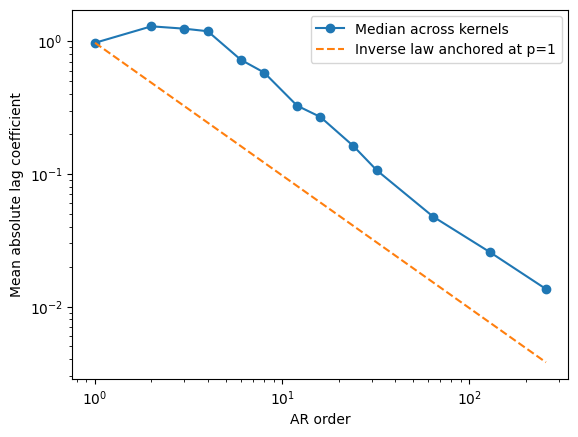

In [3]:
from threadpoolctl import threadpool_limits
from scipy.stats import spearmanr
orders = [1,2,3,4,6,8,12,16,24,32,64,128,256]
rows = []
with threadpool_limits(limits=1):
    for i,f in enumerate(FUNCTIONS):
        rng = np.random.default_rng(GLOBAL_SEED+100000+i)
        x = draw_from_factor(stable_factor(f['covariance']), N_TRAIN, rng)
        train = (x-x.mean())/(x.std()+1e-12)
        for p in orders:
            phi = fit_ar(train,p).coefficients
            rows.append(dict(kernel=f['id'],family=f['family'],category=f['category'],p=p,mean_abs=np.abs(phi).mean(),signed=phi.mean(),l1=np.abs(phi).sum()))
df=pd.DataFrame(rows)
assert len(df)==53*13
stats=[]
for kernel,g in df.groupby('kernel'):
    stats.append(dict(kernel=kernel,slope=np.polyfit(np.log(g.p),np.log(g.mean_abs),1)[0],rho=spearmanr(g.p,g.mean_abs).statistic,l1_ratio=g.l1.iloc[-1]/g.l1.iloc[0]))
stats=pd.DataFrame(stats)
table=df.groupby('p')[['mean_abs','signed','l1']].median()
display(table,stats.describe())
ax=table.mean_abs.plot(logx=True,logy=True,marker='o',label='Median across kernels')
ax.plot(orders,table.mean_abs.iloc[0]/np.array(orders),'--',label='Inverse law anchored at p=1')
ax.set(xlabel='AR order',ylabel='Mean absolute lag coefficient');ax.legend();plt.show()


In [4]:
# COMPLETE EXPERIMENT RECORD
from pathlib import Path
import hashlib, importlib.metadata as md
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
source=root/'experiments/autoregressive_process_coverage/AR/01_kernelsynth_ar_coverage.ipynb'
record=dict(question='Does mean lag coefficient magnitude scale as 1/p within KernelSynth cases?',hypothesis='Negative slope; exact inverse law predicts exponent -1 and constant L1.',config=dict(orders=orders,seed=GLOBAL_SEED,seed_policy='composition +10000; draws +100000+case index',N_TRAIN=N_TRAIN,length=LENGTH,ridge=RIDGE,intercept='unpenalized and excluded',manifest=[{k:f[k] for k in ('id','formula','category','family')} for f in FUNCTIONS]),provenance=dict(source=str(source.relative_to(root)),sha256=hashlib.sha256(source.read_bytes()).hexdigest(),git=subprocess.check_output(['git','rev-parse','HEAD'],cwd=root,text=True).strip(),python=sys.version,packages={k:md.version(k) for k in ['numpy','pandas','scipy','scikit-learn']}),metrics=dict(per_fit=rows,per_kernel=stats.to_dict('records')),scientific_summary=f"{(stats.slope<0).sum()}/53 negative fitted exponents; median exponent {stats.slope.median():.3f}; median endpoint L1 ratio {stats.l1_ratio.median():.3f}. Descriptive finite bank with repeated entries and sampled composites; unrestricted ridge fits do not estimate a stable AST sampling prior.",reproduction='From repository root: python -m jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=-1 experiments/autoregressive_process_coverage/lag_coefficient_scaling/01_kernelsynth_ar.ipynb')
print(json.dumps(record,indent=1))


{
 "question": "Does mean lag coefficient magnitude scale as 1/p within KernelSynth cases?",
 "hypothesis": "Negative slope; exact inverse law predicts exponent -1 and constant L1.",
 "config": {
  "orders": [
   1,
   2,
   3,
   4,
   6,
   8,
   12,
   16,
   24,
   32,
   64,
   128,
   256
  ],
  "seed": 20260930,
  "seed_policy": "composition +10000; draws +100000+case index",
  "N_TRAIN": 16,
  "length": 1024,
  "ridge": 1e-05,
  "intercept": "unpenalized and excluded",
  "manifest": [
   {
    "id": "periodic_01_p24",
    "formula": "ExpSineSquared(length_scale=1, periodicity=24/1024)",
    "category": "base",
    "family": "periodic"
   },
   {
    "id": "periodic_02_p48",
    "formula": "ExpSineSquared(length_scale=1, periodicity=48/1024)",
    "category": "base",
    "family": "periodic"
   },
   {
    "id": "periodic_03_p96",
    "formula": "ExpSineSquared(length_scale=1, periodicity=96/1024)",
    "category": "base",
    "family": "periodic"
   },
   {
    "id": "periodic_